<h1><center> Logistic Regression

<h3> 1- Régression logistique avec 2 caractéristiques (Sigmoid function)

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt


from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report,log_loss

In [2]:
X, y = make_classification(n_samples=200, n_features=2, n_redundant=0, random_state=42)

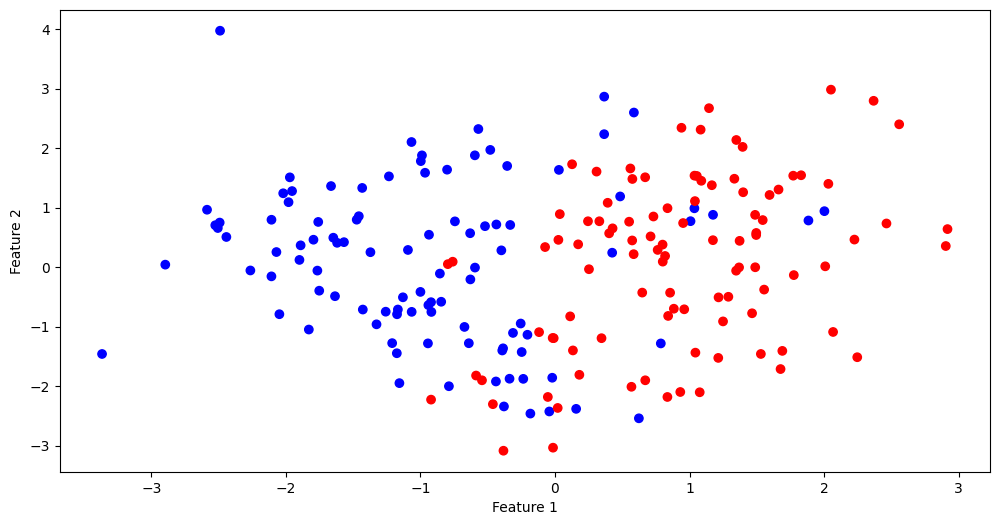

In [3]:
plt.figure(figsize=(12,6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='bwr')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()

- X[:, 0] → x-axis (feature 1)

- X[:, 1] → y-axis (feature 2)

- c=y → colors each point by its class (0 or 1)

- cmap='bwr' → blue for one class, red for the other

- edgecolors='k' → adds a black edge to points (for clarity)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)
print(len(X_train), len(y_train), len(X_test), len(y_test))

160 160 40 40


In [5]:
lr_model = LogisticRegression()


In [6]:
lr_model.fit(X_train, y_train)

LogisticRegression()

In [7]:
y_pred = lr_model.predict(X_test)

In [8]:
print("Accuracy:", accuracy_score(y_test, y_pred)*100,"%")
print("\nMatrice de confusion:\n", confusion_matrix(y_test, y_pred))
print("\nRapport de classification:\n", classification_report(y_test, y_pred))

Accuracy: 80.0 %

Matrice de confusion:
 [[14  5]
 [ 3 18]]

Rapport de classification:
               precision    recall  f1-score   support

           0       0.82      0.74      0.78        19
           1       0.78      0.86      0.82        21

    accuracy                           0.80        40
   macro avg       0.80      0.80      0.80        40
weighted avg       0.80      0.80      0.80        40



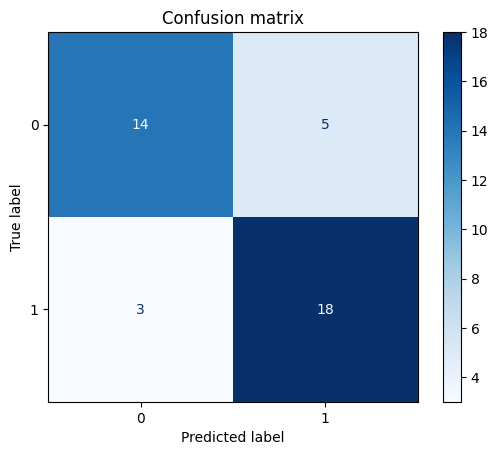

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
conf = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(conf)
disp.plot(cmap= 'Blues')
plt.title('Confusion matrix')
plt.show()

In [10]:
log_loss(y_test, y_pred)

7.20873067782343

In [11]:
lr_model.coef_

array([[ 2.01388452, -0.18643299]])

In [12]:
lr_model.intercept_

array([-0.10596372])

<h3> 2- Régression logistique avec 2 caractéristiques (Softmax function)

In [68]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [69]:
X, y = make_classification(n_samples=300,
                            n_features=2,
                            n_redundant=0,
                            n_informative=2,
                            n_clusters_per_class=1,
                            n_classes=3,
                            random_state= 42)

In [70]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)
print(len(X_train), len(y_train))

240 240


In [71]:
np.unique(y)

array([0, 1, 2])

In [72]:
model_lr = LogisticRegression(multi_class= 'multinomial')
model_lr.fit(X_train, y_train)

c:\Users\hp\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


LogisticRegression(multi_class='multinomial')

In [73]:
y_pred = model_lr.predict(X_test)

In [74]:
print("Accuracy:", accuracy_score(y_test, y_pred)*100,"%")
print("\nMatrice de confusion:\n", confusion_matrix(y_test, y_pred))
print("\nRapport de classification:\n", classification_report(y_test, y_pred))

Accuracy: 88.33333333333333 %

Matrice de confusion:
 [[17  2  0]
 [ 3 20  0]
 [ 2  0 16]]

Rapport de classification:
               precision    recall  f1-score   support

           0       0.77      0.89      0.83        19
           1       0.91      0.87      0.89        23
           2       1.00      0.89      0.94        18

    accuracy                           0.88        60
   macro avg       0.89      0.88      0.89        60
weighted avg       0.89      0.88      0.89        60



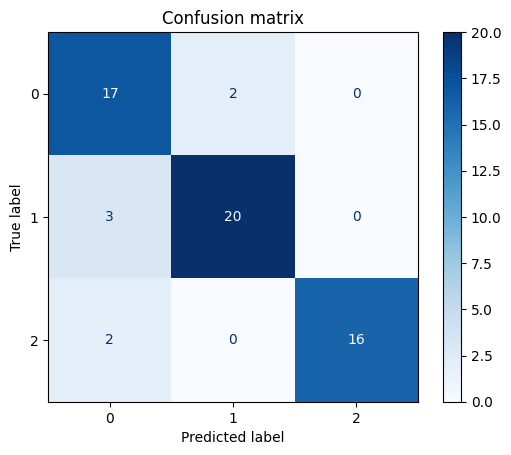

In [75]:
conf = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(conf)
disp.plot(cmap= 'Blues')
plt.title('Confusion matrix')
plt.show()

c:\Users\hp\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
c:\Users\hp\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Accuracy (OvR / Sigmoid) : 0.8777777777777778
Accuracy (Softmax)       : 0.8777777777777778


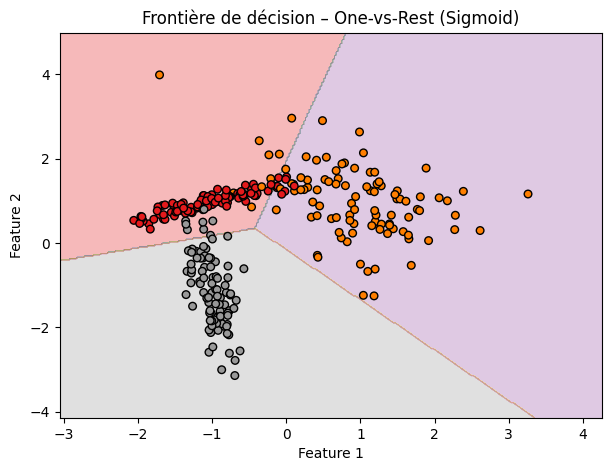

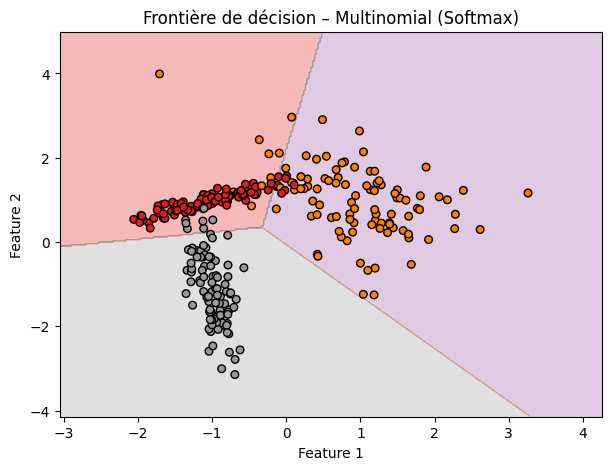

In [76]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 1️⃣ Génération d’un dataset à 3 classes
X, y = make_classification(
    n_samples=300,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    n_classes=3,
    random_state=42
)

# 2️⃣ Séparation en train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 3️⃣ Modèle 1 : One-vs-Rest (sigmoid)
model_ovr = LogisticRegression(multi_class='ovr', solver='lbfgs')
model_ovr.fit(X_train, y_train)

# 4️⃣ Modèle 2 : Multinomial (softmax)
model_softmax = LogisticRegression(multi_class='multinomial', solver='lbfgs')
model_softmax.fit(X_train, y_train)

# 5️⃣ Évaluation
print("Accuracy (OvR / Sigmoid) :", accuracy_score(y_test, model_ovr.predict(X_test)))
print("Accuracy (Softmax)       :", accuracy_score(y_test, model_softmax.predict(X_test)))

# 6️⃣ Visualisation des frontières de décision
def plot_decision_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    plt.figure(figsize=(7,5))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Set1)
    plt.scatter(X[:, 0], X[:, 1], c=y, s=30, edgecolors='k', cmap=plt.cm.Set1)
    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()

plot_decision_boundary(model_ovr, X, y, "Frontière de décision – One-vs-Rest (Sigmoid)")
plot_decision_boundary(model_softmax, X, y, "Frontière de décision – Multinomial (Softmax)")
